# 04 — Análise Exploratória
**Arquivo:** 04-analise-exploratoria.ipynb
**Objetivo:** analisar a evolução da vacância e da composição do segmento logístico a partir da Gold
**Entrada:** dados/gold/*.parquet; dados/silver/imoveis/ (consulta pontual).
**Saída:** monografia/figuras/*.png
**Onde roda:** local (.venv, pandas, matplotlib, seaborn) — **Camada:** Gold → análise

In [19]:
# Bibliotecas: pandas lê a Gold; matplotlib desenha os gráficos; seaborn só
# aplica um estilo visual mais limpo (grade clara) sobre o matplotlib.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Caminhos centralizados, no mesmo padrão dos notebooks 02 e 03. Na migração,
# só GOLD muda; FIGURAS continua local, porque as imagens vão para o Word.
RAIZ = Path("..").resolve()
GOLD = RAIZ / "dados" / "gold"
# Silver usada só para consultas pontuais de detalhe (nome e endereço de imóvel).
SILVER = RAIZ / "dados" / "silver"
FIGURAS = RAIZ / "monografia" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

# Carrega as duas tabelas da Gold. São pequenas, então cabem inteiras na memória.
df_segmento = pd.read_parquet(GOLD / "vacancia_segmento_trimestral.parquet")
df_fundo = pd.read_parquet(GOLD / "vacancia_fundo_trimestral.parquet")

# Conferência: os tamanhos precisam bater com o que o notebook 03 gravou.
print("Gold 1 (segmento):", len(df_segmento), "linhas | Esperado 26?", len(df_segmento) == 26)
print("Gold 2 (fundo):", len(df_fundo), "linhas | Esperado 892?", len(df_fundo) == 892)

# Estilo padrão de todos os gráficos do notebook: fundo branco com grade leve,
# legível impresso em preto e branco.
sns.set_theme(style="whitegrid")

Gold 1 (segmento): 26 linhas | Esperado 26? True
Gold 2 (fundo): 892 linhas | Esperado 892? True


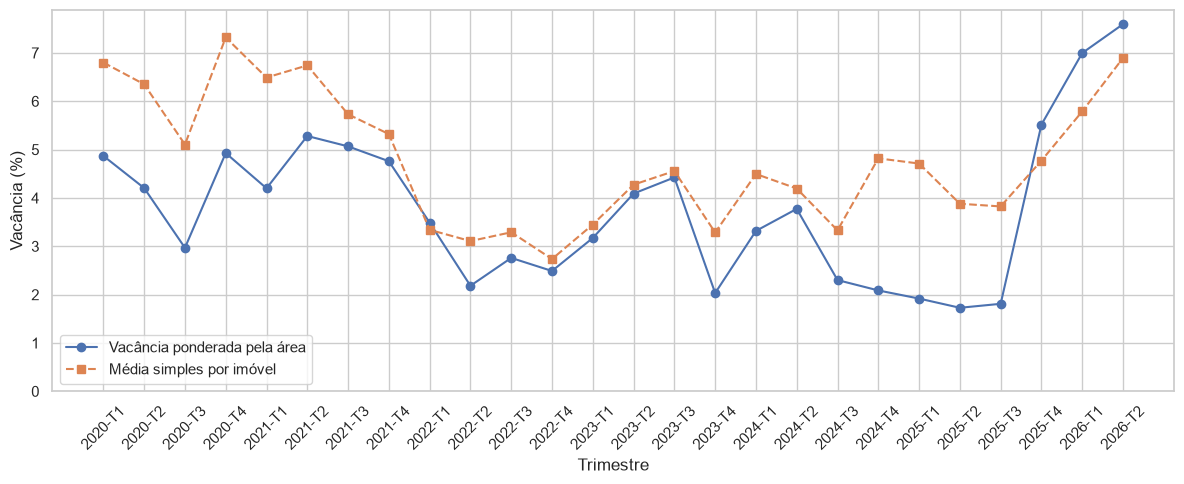

In [20]:
# Converte para porcentagem só para exibir; a Gold continua na escala 0 a 1.
ponderada_pct = df_segmento['vacancia_ponderada'] * 100
simples_pct = df_segmento['vacancia_media_simples'] * 100

# Desenha as duas séries no mesmo eixo, para comparar diretamente. Marcadores
# diferentes (círculo e quadrado) permitem distinguir as linhas mesmo sem cor.
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_segmento['periodo'], ponderada_pct, marker='o', label='Vacância ponderada pela área')
ax.plot(df_segmento['periodo'], simples_pct, marker='s', linestyle='--', label='Média simples por imóvel')

# Rótulos dos eixos e legenda. Sem título interno: pela ABNT, o título da
# figura vai no texto da monografia. Os rótulos do eixo X são girados porque
# 26 períodos não cabem na horizontal.
ax.set_xlabel('Trimestre')
ax.set_ylabel('Vacância (%)')
ax.set_ylim(bottom=0)
ax.legend()
ax.tick_params(axis='x', rotation=45)

# Ajusta margens e salva em alta resolução (300 dpi, padrão para impressão)
# antes de exibir. bbox_inches='tight' corta a borda branca em excesso.
fig.tight_layout()
fig.savefig(FIGURAS / "fig01_vacancia_ponderada_simples.png", dpi=300, bbox_inches='tight')
plt.show()

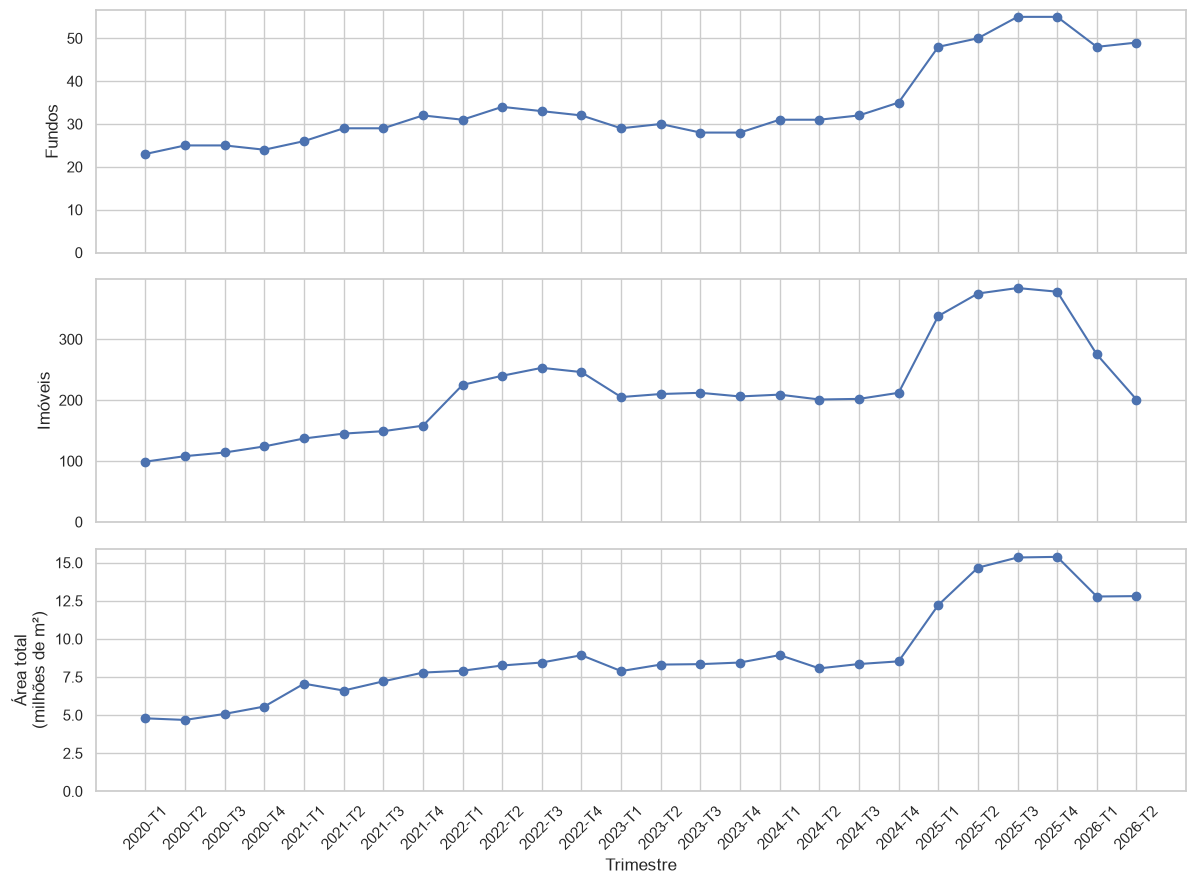

In [21]:
# Três painéis empilhados com o mesmo eixo X (sharex=True): cada medida ganha
# escala própria, e os trimestres ficam alinhados verticalmente para comparar.
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

# Painel 1: quantidade de fundos com imóveis aprovados em cada trimestre.
axes[0].plot(df_segmento['periodo'], df_segmento['qtd_fundos'], marker='o')
axes[0].set_ylabel('Fundos')

# Painel 2: quantidade de imóveis (registros) usados em cada trimestre.
axes[1].plot(df_segmento['periodo'], df_segmento['qtd_registros'], marker='o')
axes[1].set_ylabel('Imóveis')

# Painel 3: área total em milhões de m². A divisão é só para leitura;
# a Gold continua em m².
axes[2].plot(df_segmento['periodo'], df_segmento['area_total_m2'] / 1_000_000, marker='o')
axes[2].set_ylabel('Área total\n(milhões de m²)')

# O mesmo ajuste nos três painéis: o laço percorre a lista de painéis e
# aplica o eixo Y a partir de zero em cada um, sem repetir a linha três vezes.
for ax in axes:
    ax.set_ylim(bottom=0)

# Rótulos do eixo X só no painel de baixo: com sharex, os de cima não mostram
# os trimestres, então girar ou nomear o eixo lá não teria efeito.
axes[2].set_xlabel('Trimestre')
axes[2].tick_params(axis='x', rotation=45)

# Salva antes de exibir, no mesmo padrão do gráfico 1.
fig.tight_layout()
fig.savefig(FIGURAS / "fig02_evolucao_amostra.png", dpi=300, bbox_inches='tight')
plt.show()

In [22]:
# Recorta a Gold 2 nos dois trimestres do salto da área vaga.
periodos = ['2025-T3', '2025-T4']
df_salto = df_fundo[df_fundo['periodo'].isin(periodos)]

# Gira a tabela: uma linha por fundo, uma coluna de área vaga por trimestre.
# Cada fundo tem no máximo um valor por trimestre, então a agregação padrão
# do pivot_table (média) devolve o próprio valor.
tabela = df_salto.pivot_table(index='CNPJ_Fundo_Classe', columns='periodo',
                              values='area_vaga_m2')

# Marca a presença em cada trimestre ANTES de preencher os vazios, para não
# perder a informação de quem entrou ou saiu da amostra.
tabela['presente_T3'] = tabela['2025-T3'].notna()
tabela['presente_T4'] = tabela['2025-T4'].notna()

# Fundo ausente num trimestre conta como zero de área vaga nele: se entrou no
# T4, toda a sua área vaga é aumento para o segmento.
tabela[periodos] = tabela[periodos].fillna(0)

# Variação de cada fundo e ordenação do maior aumento para o menor.
tabela['variacao_m2'] = tabela['2025-T4'] - tabela['2025-T3']
tabela = tabela.sort_values('variacao_m2', ascending=False)

# Validação: a soma das variações dos fundos tem que reproduzir o aumento do
# segmento na Gold 1 (848.553 − 277.585 = 570.968 m²).
vaga_t3 = df_segmento.loc[df_segmento['periodo'] == '2025-T3', 'area_vaga_m2'].iloc[0]
vaga_t4 = df_segmento.loc[df_segmento['periodo'] == '2025-T4', 'area_vaga_m2'].iloc[0]
aumento_segmento = vaga_t4 - vaga_t3
print("Aumento do segmento (m²):", round(aumento_segmento))
print("Soma das variações bate?", abs(tabela['variacao_m2'].sum() - aumento_segmento) < 0.01)

# Concentração: quanto do aumento total os cinco maiores aumentos explicam.
participacao_top5 = tabela['variacao_m2'].head(5).sum() / aumento_segmento
print("Participação dos 5 maiores no aumento:", round(participacao_top5 * 100, 1), "%")

tabela.head(10)

Aumento do segmento (m²): 570968
Soma das variações bate? True
Participação dos 5 maiores no aumento: 100.6 %


periodo,2025-T3,2025-T4,presente_T3,presente_T4,variacao_m2
CNPJ_Fundo_Classe,,,,,
63.574.240/0001-10,0.000000,338477.530000,False,True,338477.530000
16.671.412/0001-93,6427.316504,128176.316504,True,True,121749.000000
35.652.278/0001-28,0.000000,67420.203094,True,True,67420.203094
30.629.603/0001-18,8973.297000,45059.217000,True,True,36085.920000
51.786.271/0001-55,0.000000,10845.000000,True,True,10845.000000
14.217.108/0001-45,0.000000,6022.015536,True,True,6022.015536
40.346.049/0001-15,44836.730400,48912.796800,True,True,4076.066400
27.486.542/0001-72,0.000000,2691.948490,True,True,2691.948490
26.502.794/0001-85,47079.168630,47208.180993,True,True,129.012364


In [23]:
# Classifica cada fundo pela presença nos dois trimestres. ~ é NÃO e & é E,
# como no filtro LDAP do AD: "entrou" = NÃO presente no T3 E presente no T4.
entrou = ~tabela['presente_T3'] & tabela['presente_T4']
saiu = tabela['presente_T3'] & ~tabela['presente_T4']
permaneceu = tabela['presente_T3'] & tabela['presente_T4']

# Soma a variação dentro de cada grupo: são as três parcelas do aumento.
decomposicao = pd.DataFrame({
    'qtd_fundos': [entrou.sum(), saiu.sum(), permaneceu.sum()],
    'variacao_m2': [tabela.loc[entrou, 'variacao_m2'].sum(),
                    tabela.loc[saiu, 'variacao_m2'].sum(),
                    tabela.loc[permaneceu, 'variacao_m2'].sum()],
}, index=['Entraram no T4', 'Saíram após o T3', 'Presentes nos dois'])

# Participação de cada parcela no aumento total, já em % para leitura.
decomposicao['participacao_pct'] = decomposicao['variacao_m2'] / aumento_segmento * 100

# Validação: as três parcelas têm que somar o aumento do segmento.
print("Parcelas somam o aumento?", abs(decomposicao['variacao_m2'].sum() - aumento_segmento) < 0.01)
decomposicao.round(1)

Parcelas somam o aumento? True


,qtd_fundos,variacao_m2,participacao_pct
Entraram no T4,4,338477.5,59.3
Saíram após o T3,4,0.0,0.0
Presentes nos dois,51,232490.8,40.7


In [24]:
# Histórico 2025–2026 dos três maiores aumentos, na Gold 2: mostra se a área
# vaga é de poucos imóveis grandes e se continuou vaga nos trimestres seguintes.
top3 = tabela.head(3).index
historico = df_fundo[df_fundo['CNPJ_Fundo_Classe'].isin(top3) & (df_fundo['ano'] >= 2025)]
historico[['CNPJ_Fundo_Classe', 'periodo', 'qtd_registros', 'area_total_m2',
           'area_vaga_m2', 'vacancia_ponderada']].sort_values(['CNPJ_Fundo_Classe', 'periodo'])

,CNPJ_Fundo_Classe,periodo,qtd_registros,area_total_m2,area_vaga_m2,vacancia_ponderada
597,16.671.412/0001-93,2025-T1,5,255512.07,0.000000,0.000000
644,16.671.412/0001-93,2025-T2,5,255512.07,6427.000000,0.025153
694,16.671.412/0001-93,2025-T3,5,255512.07,6427.316504,0.025155
748,16.671.412/0001-93,2025-T4,5,255512.07,128176.316504,0.501645
802,16.671.412/0001-93,2026-T1,5,192350.00,63176.316504,0.328445
850,16.671.412/0001-93,2026-T2,5,192350.00,0.000000,0.000000
617,35.652.278/0001-28,2025-T1,9,460413.56,0.000000,0.000000
664,35.652.278/0001-28,2025-T2,9,460413.56,0.000000,0.000000
714,35.652.278/0001-28,2025-T3,9,460413.56,0.000000,0.000000
767,35.652.278/0001-28,2025-T4,9,460413.56,67420.203094,0.146434


In [25]:
# Consulta pontual na Silver: identifica o imóvel único do fundo que entrou
# no 2025-T4 com 338 mil m² vagos. Lê a pasta particionada inteira (pequena)
# e filtra pelo CNPJ.
FUNDO_ENTRANTE = '63.574.240/0001-10'
df_silver = pd.read_parquet(SILVER / "imoveis")
df_silver[df_silver['CNPJ_Fundo_Classe'] == FUNDO_ENTRANTE][
    ['Data_Referencia', 'Nome_Imovel', 'Endereco', 'Area', 'Percentual_Vacancia']]

,Data_Referencia,Nome_Imovel,Endereco,Area,Percentual_Vacancia
5129,2025-12-31,Terminal Multimodal de Camaçari,"Via de Ligação , Polo Petroquimico de Camaçari...",338477.53,1.0
5583,2026-03-31,Terminal Multimodal de Camaçari,"Via de Ligação , Polo Petroquimico de Camaçari...",338477.53,1.0
5584,2026-06-30,Terminal Multimodal de Camaçari,"Via de Ligação , Polo Petroquimico de Camaçari...",338477.53,1.0


Soma dos grupos bate com a Gold 1? True


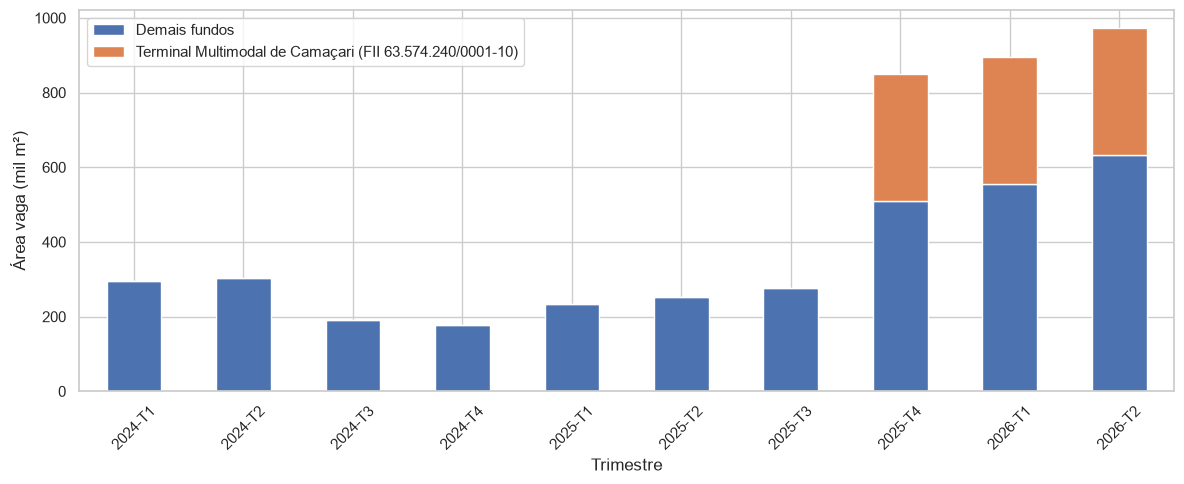

In [26]:
# Recorta a Gold 2 a partir de 2024 e rotula cada linha: fundo entrante ou
# demais. O rótulo começa igual para todos e é trocado só para o CNPJ em destaque.
recorte = df_fundo[df_fundo['ano'] >= 2024].copy()
recorte['grupo'] = 'Demais fundos'
recorte.loc[recorte['CNPJ_Fundo_Classe'] == FUNDO_ENTRANTE, 'grupo'] = 'Fundo 63.574.240/0001-10'

# Soma a área vaga por período e grupo, em mil m² para leitura. fill_value=0
# preenche os períodos em que o fundo entrante ainda não existia.
serie = recorte.pivot_table(index='periodo', columns='grupo', values='area_vaga_m2',
                            aggfunc='sum', fill_value=0) / 1000

# Validação: em cada período, os dois grupos somados reproduzem a Gold 1.
total_gold1 = df_segmento.loc[df_segmento['ano'] >= 2024, 'area_vaga_m2'].values / 1000
print("Soma dos grupos bate com a Gold 1?", abs(serie.sum(axis=1).values - total_gold1).max() < 0.001)

# Barras empilhadas: "Demais fundos" embaixo e o fundo entrante em cima, para o
# bloco novo aparecer como acréscimo sobre a base.
fig, ax = plt.subplots(figsize=(12, 5))
serie[['Demais fundos', 'Fundo 63.574.240/0001-10']].plot(kind='bar', stacked=True, ax=ax)
ax.legend(['Demais fundos', 'Terminal Multimodal de Camaçari (FII 63.574.240/0001-10)'],
          title=None)
ax.set_xlabel('Trimestre')
ax.set_ylabel('Área vaga (mil m²)')
ax.set_ylim(bottom=0)
ax.tick_params(axis='x', rotation=45)

# Salva antes de exibir, no padrão da DA-28.
fig.tight_layout()
fig.savefig(FIGURAS / "fig03_area_vaga_fundo_entrante.png", dpi=300, bbox_inches='tight')
plt.show()

Registros sem faixa: 0
Total de registros: 5607 | Esperado 5607? True
faixa_vacancia  0% (locado)  Até 10%  10% a 50%  50% a 100%  100% (vago)
ano                                                                     
2020                   85.8      3.1        5.4         1.1          4.5
2021                   85.4      3.1        6.6         1.4          3.6
2022                   90.0      2.9        5.4         0.2          1.5
2023                   86.3      4.3        7.1         0.8          1.4
2024                   85.2      5.2        7.2         0.4          2.1
2025                   88.0      4.4        4.3         0.6          2.6
2026                   85.9      4.6        4.8         0.4          4.2


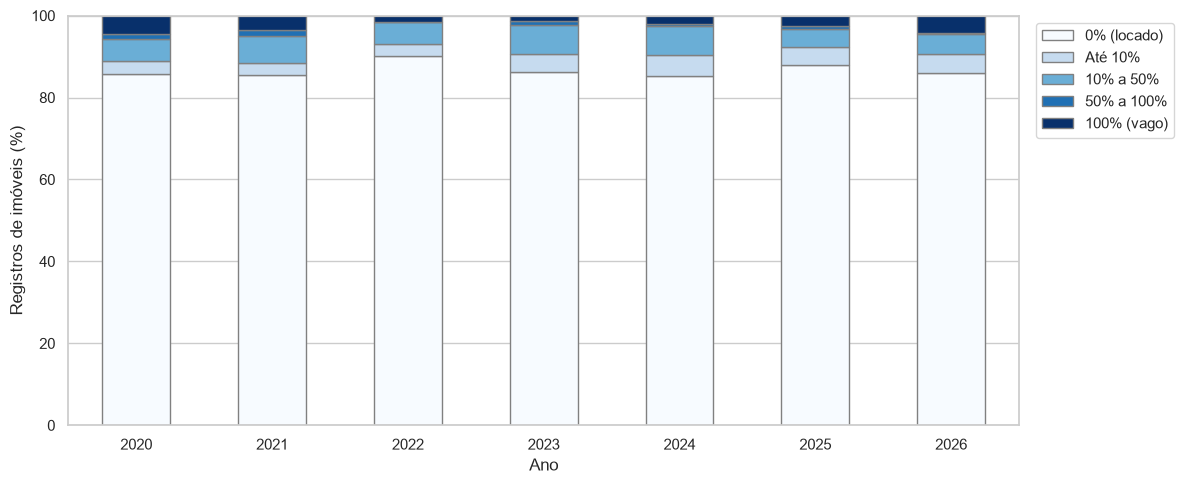

In [27]:
import numpy as np

# Classifica cada registro de imóvel em uma faixa de vacância. np.select avalia
# as condições em ordem e a primeira verdadeira vence (como políticas de
# firewall), então cada condição só precisa do limite superior.
vac = df_silver['Percentual_Vacancia']
condicoes = [vac == 0, vac <= 0.10, vac <= 0.50, vac < 1, vac == 1]
faixas = ['0% (locado)', 'Até 10%', '10% a 50%', '50% a 100%', '100% (vago)']
df_silver['faixa_vacancia'] = np.select(condicoes, faixas, default='sem_faixa')

# Conferência: nenhum registro pode ficar sem faixa (a Silver só tem
# vacância entre 0 e 1, garantido pelas regras de qualidade do notebook 02).
print("Registros sem faixa:", (df_silver['faixa_vacancia'] == 'sem_faixa').sum())
print("Total de registros:", len(df_silver), "| Esperado 5607?", len(df_silver) == 5607)

# Tabela cruzada ano × faixa em porcentagem: normalize='index' faz cada linha
# (cada ano) somar 1, e o ×100 converte para %, só para exibição.
distribuicao = pd.crosstab(df_silver['ano'], df_silver['faixa_vacancia'],
                           normalize='index')[faixas] * 100
print(distribuicao.round(1))

# Barras empilhadas de 100%, uma por ano. Escala de azuis (claro = locado,
# escuro = vago), legível em impressão preto e branco. A legenda fica fora da
# área do gráfico para não cobrir as barras.
fig, ax = plt.subplots(figsize=(12, 5))
distribuicao.plot(kind='bar', stacked=True, ax=ax, colormap='Blues', edgecolor='grey')
ax.set_xlabel('Ano')
ax.set_ylabel('Registros de imóveis (%)')
ax.set_ylim(0, 100)
ax.tick_params(axis='x', rotation=0)
ax.legend(title=None, bbox_to_anchor=(1.01, 1), loc='upper left')

# Salva antes de exibir, no padrão da DA-28.
fig.tight_layout()
fig.savefig(FIGURAS / "fig04_distribuicao_vacancia_faixas.png", dpi=300, bbox_inches='tight')
plt.show()

## Conclusões do notebook 04

**Figuras geradas** (monografia/figuras/, padrão DA-28)

- `fig01_vacancia_ponderada_simples.png`: vacância ponderada × média simples, de 2020-T1 a 2026-T2.
- `fig02_evolucao_amostra.png`: fundos, imóveis e área total por trimestre.
- `fig03_area_vaga_fundo_entrante.png`: área vaga de 2024-T1 a 2026-T2, com destaque para o Terminal Multimodal de Camaçari.
- `fig04_distribuicao_vacancia_faixas.png`: distribuição da vacância por faixas, por ano.

**Achados**

- A vacância ponderada ficou abaixo da simples na maior parte do período. A exceção mínima é 2022-T1 (+0,15 ponto). A partir de 2025-T4 a ponderada passa a ficar acima e chega a 7,6% em 2026-T2.
- A amostra cresce em degraus: em 2025-T1 os fundos passam de 35 para 48 e a área de 8,5 para 12,2 milhões de m². Há efeito de composição: a ponderada cai enquanto a área cresce.
- O salto de 2025-T4 (+570.968 m² vagos) se decompõe em 59,3% de entrada na amostra (um único imóvel, o Terminal Multimodal de Camaçari, 338.478 m², 100% vago) e 40,7% de desocupação em fundos presentes nos dois trimestres (DA-29).
- O Terminal de Camaçari representa 37,8% da área vaga em 2026-T1 e 34,8% em 2026-T2. Sem os três fundos de maior aumento, a área vaga dos demais sobe de 314.479 m² (2025-T4) para 566.596 m² (2026-T2).
- Entre 85,2% e 90,0% dos registros de imóveis têm vacância zero em todos os anos. A vacância do segmento é movida por uma cauda pequena, cujo peso depende do tamanho dos imóveis.

**Hipóteses não verificadas** (limitações ou trabalhos futuros)

- O salto de 2025-T1 viria da reclassificação de fundos existentes como Logística.
- A queda de registros em 2026 com área estável viria do agrupamento de imóveis nos informes.
- O motivo da vacância integral do Terminal de Camaçari não está nos dados.

**Limitações**

- Os percentuais da figura 4 são de registros, não de imóveis distintos (sem identificador único na CVM).
- 2026 tem apenas dois trimestres.
- O segmento Logística reúne ativos heterogêneos, conforme a classificação declarada pelos fundos.